In [17]:
import pandas as pd
import numpy as np
import pickle
import glob
from scipy.stats import norm
from scipy.stats import gaussian_kde
import os

import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
from scipy.stats import gaussian_kde

import matplotlib as mpl
matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'
# import scipy.io as sio

In [18]:
def plotSTA(sta, ste, sta_error, Timepost, TimeHistory, Fs, fig, ax, mothID, unit_label):
    time_axis = np.arange(-TimePost, TimeHistory, 1/Fs)
    t_ms = time_axis * 1000  # convert to ms for x axis
    n_spikes = len(ste)
   
    ax.fill_between(t_ms, np.flip(sta-sta_error, axis=0), np.flip(sta+sta_error, axis=0),
                    color='darkgrey', alpha=0.5)
    ax.plot(t_ms, np.flip(sta), 'k', linewidth=2, label='Mean (STA)')
    ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
    ax.set_xlim(20, -2)  # ms, reversed as original
    ax.set_xlabel('Time (ms)', fontsize=15)
    ax.set_ylabel('Proboscis Movement (degrees)', fontsize=15)
    ax.set_title(f'Spike-Triggered Average ± SD {mothID} {unit_label} (n={n_spikes})', fontsize=15)
    ax.tick_params(labelsize=10)
    plt.tight_layout()

In [19]:
def plotNLD(ax, bin_edges, counts_ste, counts_prior, nld):
    
    # Calculate the width of each bar
    bin_widths = np.diff(bin_edges)
    
    ax[0].bar(bin_centers[:-1], counts_prior, width=bin_widths, align='center', edgecolor='black', color='orange')
    ax[0].bar(bin_centers[:-1], counts_ste, width=bin_widths, align='center', edgecolor='black', color='blue', alpha = 0.8)
    ax[1].plot(bin_centers[:-1], nld, 'o-', color='black')
    ax[1].set_xlabel('STA-Stimulus Similarity', fontsize=15)
    ax[1].set_ylabel('Probability of Firing Rate (Hz)', fontsize=15)

In [20]:
# input all parameters
Fs = 3e4
TimeHistory = 20e-3 # in seconds
TimePost = 2e-3 # in seconds
Num_Repeats = 30

In [21]:
filepath_model = glob.glob('./dataFolder/5_1DCompModel/*.pickle')

out_path = './dataFolder/Figures/3_1DCompModel/'
os.makedirs(out_path, exist_ok=True)

In [22]:
# instead of going through all data, make list of moth and unit IDs that you want to run this analysis for

moth_unit = [('m23', 'unit_1'),
             ('m29', 'unit_1'),
             ('m30', 'unit_1'),
             ('m31', 'unit_1'),
             ('m31', 'unit_2'),
             ('m31', 'unit_3')]

In [23]:
filepath_model[0]

'./dataFolder/5_1DCompModel\\m23_unit_1_EncodingModel.pickle'

processing m23 and unit_1
processing m29 and unit_1
processing m30 and unit_1
processing m31 and unit_1
processing m31 and unit_2
processing m31 and unit_3


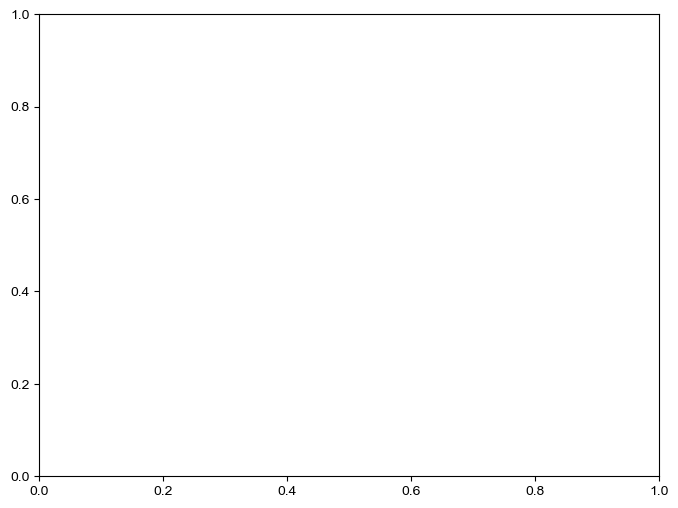

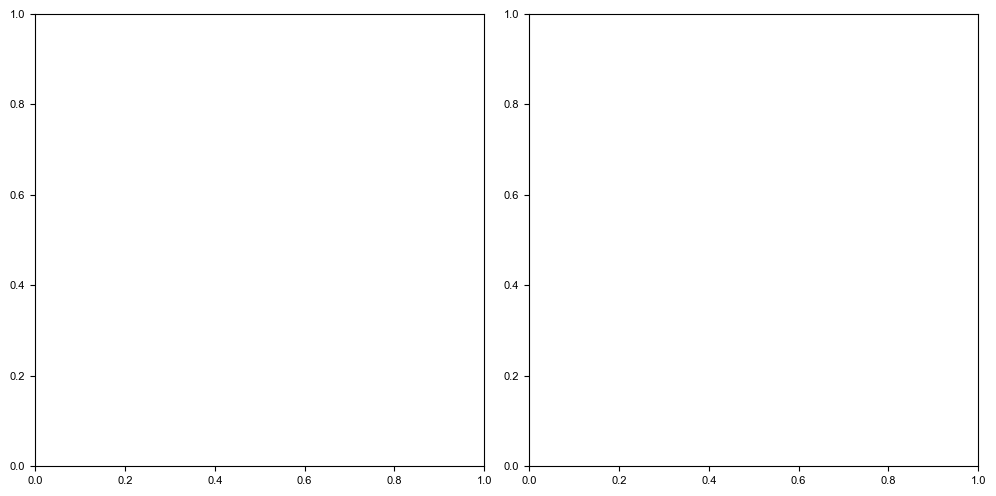

In [24]:
# read in all the data

fig_sta, ax_sta = plt.subplots(figsize=(8, 6))
fig_nld, ax_nld = plt.subplots(1,2, figsize=(10, 5))

for filename in filepath_model:
    name = os.path.basename(filename).split('_')[0]
    unitID = "_".join(os.path.basename(filename).split('_')[1:3])
    
    print(f'processing {name} and {unitID}')
    
    ########## get the data files #########################  
    with open(filename, 'rb') as f:
                savedModel = pickle.load(f)
    
    ste = savedModel[0]
    sta = savedModel[1]
    sta_error = savedModel[2]
    prior_ensemble = savedModel[3]
    prior_mean = savedModel[4]
    prior_error = savedModel[5]
    prior_std = savedModel[6]
    mean_fire_rate = savedModel[7]
    nld = savedModel[8]
    n_ste = savedModel[9]
    n_prior = savedModel[10]
    bin_centers = savedModel[11]
    
    ######## plot STA ####################################
    plotSTA(sta, ste, sta_error, TimePost, TimeHistory, Fs, fig_sta, ax_sta, name, unitID)
    filename = out_path + name + '_' + unitID + '_STA.pdf'
    fig_sta.savefig(filename)
    ax_sta.cla()
    
    ######## plot prior ####################################
    plotSTA(prior_mean, prior_ensemble, prior_error, TimePost, TimeHistory, Fs, fig_sta, ax_sta, name, unitID)
    filename = out_path + name + '_' + unitID + '_prior.pdf'
    fig_sta.savefig(filename)
    ax_sta.cla()
    
    ######## plot nld ####################################
    plotNLD(ax_nld, bin_centers, n_ste, n_prior, nld)
    filename = out_path + name + '_' + unitID + '_nld.pdf'
    fig_nld.savefig(filename)
    ax_nld[0].cla()
    ax_nld[1].cla()